# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and
(b) how risky its revenue is. Last year's version modelled the stock with Fibonacci numbers and called revenue
"risky" when its variance exceeded 50,000. Here we build a more defensible model and explain why the old one is flawed.

Reusable code: `src/fishery.py`.

In [1]:
# --- Imports ----------------------------------------------------------------------

# numpy: arrays and maths
import numpy as np

# pandas: tables
import pandas as pd

# matplotlib: charts
import matplotlib.pyplot as plt

# Our own code from src/fishery.py
from src.fishery import (
    fibonacci,                    # the old baseline
    FishStock,                    # logistic growth with harvesting
    PriceModel,                   # bounded random-walk price
    RiskAssessor,                 # risk class + Value-at-Risk
    weekly_revenue,               # harvest x price
    monte_carlo_annual_revenue,   # 1,000 simulated years
)

SEED = 42
WEEKS = 52
BILLION = 1e9     # used to show UGX in billions, easier to read

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # one per harvest rate
INK = "#3b3a37"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## Task 1 – The Fibonacci baseline

In [2]:
fib_stock = fibonacci(15)
print("15 Fibonacci numbers used as 'stock':", fib_stock)
print("Ratio of the last two numbers:", round(fib_stock[-1] / fib_stock[-2], 3), "(it keeps growing ~62% every step)")

15 Fibonacci numbers used as 'stock': [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Ratio of the last two numbers: 1.618 (it keeps growing ~62% every step)


**Why unbounded Fibonacci growth is biologically unrealistic.** Fibonacci numbers grow by about 62% every step
*forever*, so the "stock" never stops increasing. A real lake has limited food, oxygen and breeding space, so as fish
become crowded their growth slows and eventually stops at the lake's **carrying capacity**. The Fibonacci model also
has no deaths, no fishing and no environmental effects (such as the Nile perch introduction or water hyacinth), so it
can't answer the question we care about: *what happens to the stock when we harvest it?* After 50 steps it would
predict more tonnes of fish than the lake has litres of water.

## Task 2 – The `FishStock` class: logistic growth with harvesting

$$N(t+1) = N(t) + r\,N(t)\left(1 - \frac{N(t)}{K}\right) - h\,N(t)$$

* **r = 0.4**: growth rate when there is plenty of room
* **K = 10,000 t**: carrying capacity (the most fish the lake can hold)
* **N(0) = 4,000 t**: starting stock
* **h**: share of the stock caught each week (we start with h = 0.10)

In [3]:
stock_model = FishStock(growth_rate=0.4, capacity=10_000, initial_stock=4_000, harvest_rate=0.10)
print(stock_model)

stock, harvest = stock_model.simulate(WEEKS)     # stock has 53 values, harvest has 52
print(f"Stock after 52 weeks: {stock[-1]:,.0f} t")
print(f"Total catch in the year: {harvest.sum():,.0f} t")
print(f"Theory says the stock settles at K(1 - h/r) = {stock_model.long_run_stock():,.0f} t")

FishStock(r=0.4, K=10000, N0=4000, h=0.1)
Stock after 52 weeks: 7,500 t
Total catch in the year: 37,363 t
Theory says the stock settles at K(1 - h/r) = 7,500 t


## Task 3 – The `PriceModel` class and weekly revenue

The price starts at **UGX 12,000/kg** and moves randomly each week (a *random walk*), but it is kept between
**9,000 and 16,000** (bounds). Revenue = harvest (kg) × price.

In [4]:
price_model = PriceModel(start_price=12_000, lower=9_000, upper=16_000, weekly_change_sd=400, seed=SEED)
prices = price_model.simulate(WEEKS)
revenue = weekly_revenue(harvest, prices)       # UGX per week

pd.DataFrame({"catch (t)": harvest, "price (UGX/kg)": prices,
              "revenue (UGX bn)": revenue / BILLION}, index=pd.RangeIndex(1, WEEKS + 1, name="week")).head(8).round(2)

,catch (t),price (UGX/kg),revenue (UGX bn)
week,,,
1,400.00,12000.00,4.80
2,456.00,12121.89,5.53
3,509.63,11705.89,5.97
4,558.63,12006.07,6.71
5,601.39,12382.30,7.45
6,637.14,11601.89,7.39
7,665.90,11081.01,7.38
8,688.30,11132.15,7.66


## Task 4 – Revenue statistics, and why "variance > 50,000" is meaningless

In [5]:
summary = RiskAssessor.summary(revenue)
for key, value in summary.items():
    print(f"{key:9s}: {value:,.3f}")
print(f"\nIs variance > 50,000?  {summary['variance'] > 50_000}  (by a factor of {summary['variance'] / 50_000:,.0f})")

mean     : 8,772,093,923.332
median   : 8,879,478,157.274
variance : 1,428,628,310,241,560,320.000
std_dev  : 1,195,252,404.407
cv       : 0.136

Is variance > 50,000?  True  (by a factor of 28,572,566,204,831)


**Why the 50,000 threshold is meaningless.** Revenue is measured in UGX, so its variance is measured in
**UGX squared**, a unit with no real-world meaning. Its size depends entirely on the scale of the numbers. Measure the same
revenue in thousands of UGX and the variance shrinks a million-fold. Measure it in US dollars and it changes again.
Our variance is about 1.4 × 10¹⁸ UGX², so it is "above 50,000" by a factor of tens of trillions, and so would *any*
real business's revenue. The threshold says nothing about risk.

The **coefficient of variation (CV = standard deviation ÷ mean)** fixes this. It has no units, so CV = 0.12 means
"revenue typically swings about 12% around its average", whatever the currency or business size.

## Task 5 – `RiskAssessor`: a CV-based rule and 5% Value-at-Risk

**Our rule** (a judgement call, stated openly):

| CV | Risk | Reasoning |
|---|---|---|
| < 0.10 | Low | swings under 10% can be absorbed by normal cash flow |
| 0.10 – 0.25 | Medium | noticeable swings: keep a cash buffer of a few weeks' costs |
| ≥ 0.25 | High | a quarter or more: wages and loan repayments are at risk |

In [6]:
assessor = RiskAssessor(low_limit=0.10, high_limit=0.25)
print("Weekly revenue CV:", round(summary["cv"], 3), "->", assessor.classify(revenue), "risk")

# Monte Carlo: 1,000 different possible years of prices -> 1,000 annual revenues
annual_revenues = monte_carlo_annual_revenue(stock_model, n_paths=1000, weeks=WEEKS, seed=SEED)
var = RiskAssessor.value_at_risk(annual_revenues, level=0.05)

print(f"\nAverage annual revenue:        UGX {annual_revenues.mean() / BILLION:,.1f} bn")
print(f"5% worst-case annual revenue:  UGX {var['revenue_at_5pct'] / BILLION:,.1f} bn")
print(f"5% Value-at-Risk (vs average): UGX {var['var_vs_mean'] / BILLION:,.1f} bn")

Weekly revenue CV: 0.136 -> Medium risk



Average annual revenue:        UGX 450.3 bn
5% worst-case annual revenue:  UGX 372.1 bn
5% Value-at-Risk (vs average): UGX 78.2 bn


**Reading the VaR:** in 1 year out of 20 (5%), annual revenue is expected to fall at least this far below the average
because of price movements alone.

## Task 6 – Scenario analysis: different harvest rates

For each harvest rate we keep the **same price path**, so any difference comes from the harvesting alone.
**MSY = rK/4 = 1,000 t per week**: the largest catch the stock can keep providing forever.
It is reached when the stock is held at K/2 = 5,000 t, which needs h = r/2 = 0.20.

In [7]:
HARVEST_RATES = [0.05, 0.10, 0.20, 0.30]
msy = FishStock().maximum_sustainable_yield()
scenario_rows = []
trajectories = {}        # h -> stock array, used for the chart

for h in HARVEST_RATES:
    model = FishStock(harvest_rate=h)
    stock_h, harvest_h = model.simulate(WEEKS)
    revenue_h = weekly_revenue(harvest_h, prices)          # same prices as before
    trajectories[h] = stock_h
    scenario_rows.append({
        "harvest rate h": h,
        "final stock (t)": stock_h[-1],
        "long-run stock (t)": model.long_run_stock(),
        "catch in final week (t)": harvest_h[-1],
        "catch vs MSY": harvest_h[-1] / msy,
        "total revenue (UGX bn)": revenue_h.sum() / BILLION,
        "revenue CV": RiskAssessor.summary(revenue_h)["cv"],
        "risk class": assessor.classify(revenue_h),
    })

scenario_table = pd.DataFrame(scenario_rows).set_index("harvest rate h")
print(f"MSY = r*K/4 = {msy:,.0f} t per week")
scenario_table.round(2)

MSY = r*K/4 = 1,000 t per week


,final stock (t),long-run stock (t),catch in final week (t),catch vs MSY,total revenue (UGX bn),revenue CV,risk class
harvest rate h,,,,,,,
0.05,8750.00,8750.0,437.50,0.44,265.10,0.15,Medium
0.10,7500.00,7500.0,750.00,0.75,456.15,0.14,Medium
0.20,4999.99,5000.0,1000.00,1.00,620.75,0.09,Low
0.30,2503.72,2500.0,751.24,0.75,516.03,0.12,Medium


## Task 7 – Charts

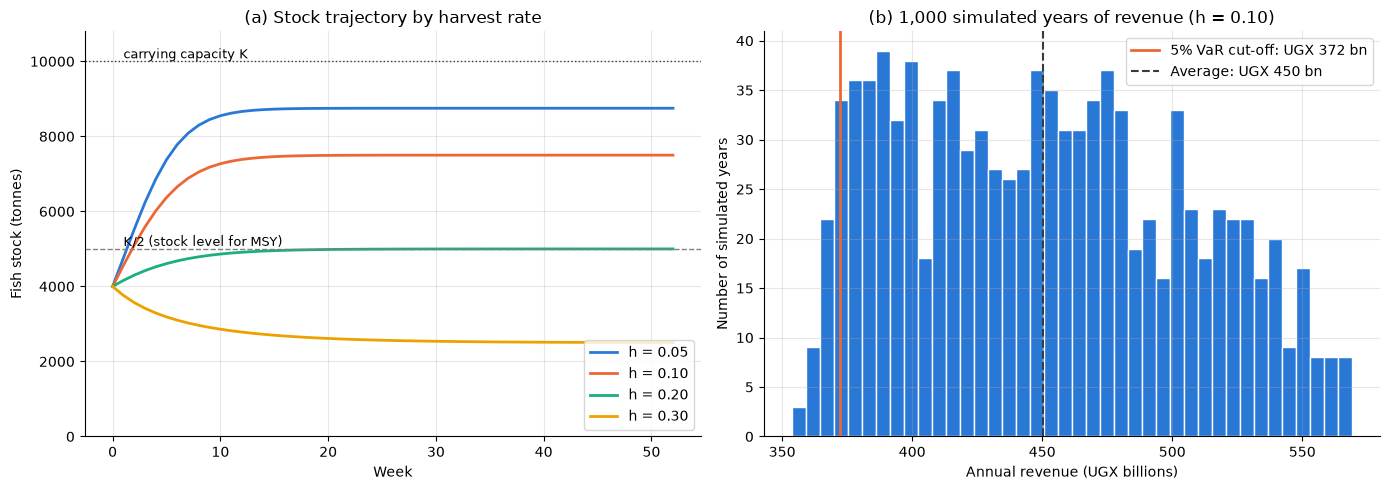

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# (a) stock trajectories, one line per harvest rate
for colour, h in zip(COLOURS, HARVEST_RATES):
    ax1.plot(range(WEEKS + 1), trajectories[h], color=colour, lw=2, label=f"h = {h:.2f}")
ax1.axhline(10_000, color=INK, ls=":", lw=1)
ax1.text(1, 10_000, "carrying capacity K", va="bottom", fontsize=9)
ax1.axhline(5_000, color="grey", ls="--", lw=1)
ax1.text(1, 5_000, "K/2 (stock level for MSY)", va="bottom", fontsize=9)
ax1.set_xlabel("Week")
ax1.set_ylabel("Fish stock (tonnes)")
ax1.set_title("(a) Stock trajectory by harvest rate")
ax1.set_ylim(0, 10_800)
ax1.legend(loc="lower right")

# (b) histogram of 1,000 simulated annual revenues with the 5% VaR marked
ax2.hist(annual_revenues / BILLION, bins=40, color=COLOURS[0], edgecolor="white")
ax2.axvline(var["revenue_at_5pct"] / BILLION, color=COLOURS[1], lw=2,
            label=f"5% VaR cut-off: UGX {var['revenue_at_5pct'] / BILLION:,.0f} bn")
ax2.axvline(annual_revenues.mean() / BILLION, color=INK, ls="--", lw=1.5,
            label=f"Average: UGX {annual_revenues.mean() / BILLION:,.0f} bn")
ax2.set_xlabel("Annual revenue (UGX billions)")
ax2.set_ylabel("Number of simulated years")
ax2.set_title("(b) 1,000 simulated years of revenue (h = 0.10)")
ax2.legend()

fig.tight_layout()
plt.show()

## Extension – A closed season (no fishing for 8 weeks a year), over 5 years

We compare fishing all year against closing weeks 1–8 of every year, over 5 years (260 weeks), using the same price
path for both. We test a moderate rate (h = 0.10) and a heavy one (h = 0.30).

In [9]:
YEARS_5 = 5 * WEEKS
long_prices = PriceModel(seed=SEED).simulate(YEARS_5)
closed_rows = []
closed_stock = {}

for h in [0.10, 0.30]:
    for closed in [0, 8]:
        stock_c, harvest_c = FishStock(harvest_rate=h).simulate(YEARS_5, closed_weeks_per_year=closed)
        revenue_c = weekly_revenue(harvest_c, long_prices)
        closed_stock[(h, closed)] = stock_c
        closed_rows.append({
            "h": h, "closed weeks/yr": closed,
            "5-yr revenue (UGX bn)": revenue_c.sum() / BILLION,
            "5-yr catch (t)": harvest_c.sum(),
            "lowest stock (t)": stock_c.min(),
            "final stock (t)": stock_c[-1],
        })

closed_table = pd.DataFrame(closed_rows).set_index(["h", "closed weeks/yr"])
closed_table.round(1)

5-yr revenue (UGX bn)  5-yr catch (t)  lowest stock (t)  \
h   closed weeks/yr                                                            
0.1 0                               2143.9        193362.5            4000.0   
    8                               1869.8        168328.5            4000.0   
0.3 0                               2204.0        198472.2            2500.0   
    8                               2325.7        210329.2            2515.1   

                     final stock (t)  
h   closed weeks/yr                   
0.1 0                         7500.0  
    8                         7500.0  
0.3 0                         2500.0  
    8                         2515.1

h = 0.10: closed season changes 5-year revenue by -12.8%
h = 0.30: closed season changes 5-year revenue by +5.5%


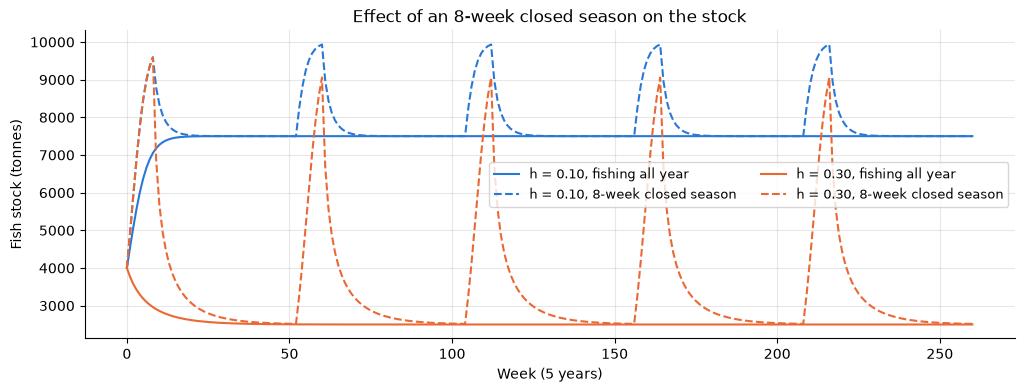

In [10]:
# Percentage change in 5-year revenue caused by the closed season, per harvest rate
for h in [0.10, 0.30]:
    open_rev = closed_table.loc[(h, 0), "5-yr revenue (UGX bn)"]
    closed_rev = closed_table.loc[(h, 8), "5-yr revenue (UGX bn)"]
    print(f"h = {h:.2f}: closed season changes 5-year revenue by {(closed_rev - open_rev) / open_rev * 100:+.1f}%")

fig, ax = plt.subplots(figsize=(12, 4))
for colour, h in zip(COLOURS[:2], [0.10, 0.30]):
    ax.plot(closed_stock[(h, 0)], color=colour, lw=1.5, label=f"h = {h:.2f}, fishing all year")
    ax.plot(closed_stock[(h, 8)], color=colour, lw=1.5, ls="--", label=f"h = {h:.2f}, 8-week closed season")
ax.set_xlabel("Week (5 years)")
ax.set_ylabel("Fish stock (tonnes)")
ax.set_title("Effect of an 8-week closed season on the stock")
ax.legend(ncol=2, fontsize=9)
plt.show()

## Findings & Limitations

**Is the harvesting rate sustainable?** Yes. At h = 0.10 the stock settles at 7,500 t (exactly the theory value
K(1 − h/r)) and the weekly catch settles at 750 t, below the maximum sustainable yield of 1,000 t. The scenarios show the
classic logistic trade-off. Catch rises with effort up to **h = 0.20**, where the stock sits at K/2 and the catch equals
the MSY (highest revenue, UGX 621 bn). Beyond that it *falls*. At h = 0.30 the cooperative works 50% harder than at
MSY, but lands only the same 750 t a week as at h = 0.10, from a stock one third the size. That is overfishing: more
effort, less fish, and a stock with little buffer against a bad year. We would recommend a target around h = 0.15.
That captures most of the MSY gain but keeps the stock well above K/2, because MSY is a knife-edge, not a safe target.

**How risky is revenue?** Weekly revenue has a CV of about 0.14 (**Medium** risk). The Monte Carlo 5% VaR is about
UGX 78 bn: in one year in twenty, price swings alone cut revenue by 17% or more below the average.

The closed-season extension shows the policy only pays off when the stock is overfished. It *raised* five-year revenue
by 5.5% at h = 0.30 but *cut* it by 12.8% at h = 0.10.

**Limitations.** With r = 0.4 per week the stock recovers in weeks, where real Lake Victoria stocks take years, so our
stock looks far more resilient than reality. The stock has no randomness (weather, illegal fishing). Price ignores
catch, although big landings usually push prices down. Revenue (UGX 450 bn a year) is far beyond one cooperative's
scale. The CV thresholds are our judgement.